# Alexander vs DeepCover MoA

## Setup

In [1]:
import gzip
from pathlib import Path
from functools import reduce

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_venn import venn2

import perturbseqr as ps
from maayanlab_bioinformatics.parse.gmt import gmt_read_dict, parse_gene_unweighted
from maayanlab_bioinformatics.harmonization.ncbi_genes import ncbi_genes_fetch

DEEPCOVER_GMT = Path("/Users/johngardner_mountsinai/work/PerturbSeqr/db/data/drug_perturbation/deepcover-moa.gmt.gz")
GENE_SETS = Path("gene_sets")
MUTATIONS = ["R239H", "R239C", "R79C", "R79H", "R239G"]
NCBI_CACHE = Path.home() / ".cache" / "ncbi_genes"
NCBI_CACHE.mkdir(parents=True, exist_ok=True)

## DeepCover stats

In [2]:
ps.library_stats().query("name == 'DeepCover MoA'")

,name,n_sets
2,DeepCover MoA,1748


In [3]:
with gzip.open(DEEPCOVER_GMT, "rt") as fh:
    deepcover_sets = gmt_read_dict(fh, parse_gene=parse_gene_unweighted)

deepcover_bg = {g.upper() for genes in deepcover_sets.values() for g in genes}
sizes = pd.Series([len(g) for g in deepcover_sets.values()])

print(f"gene sets:      {len(deepcover_sets):,}")
print(f"unique genes:   {len(deepcover_bg):,}")
print(f"distinct drugs: {len({t.split('::')[0].strip().lower() for t in deepcover_sets}):,}")
print(f"set size:       median={sizes.median():.0f}, range=[{sizes.min()}, {sizes.max()}]")

gene sets:      1,748
unique genes:   7,699
distinct drugs: 874
set size:       median=99, range=[92, 100]


## Load Alexander gene sets

In [4]:
def load(mut, direction):
    return {l.strip().upper() for l in (GENE_SETS / f"{mut}_{direction}.txt").read_text().splitlines() if l.strip()}

per_mut = {m: (load(m, "up"), load(m, "down")) for m in MUTATIONS}
alex_genes = set().union(*(up | dn for up, dn in per_mut.values()))
print(f"unique alexander genes: {len(alex_genes)}")

unique alexander genes: 362


## NCBI human protein-coding reference

In [5]:
from maayanlab_bioinformatics.harmonization import ncbi_genes_lookup

ncbi_df = ncbi_genes_fetch(organism="Mammalia/Homo_sapiens", cache_dir=str(NCBI_CACHE))
pc_symbols = set(ncbi_df.loc[ncbi_df["type_of_gene"] == "protein-coding", "Symbol"].str.upper())

# ncbi_genes_lookup() returns synonym -> official symbol (ambiguity-safe).
_raw_lookup = ncbi_genes_lookup("Mammalia/Homo_sapiens", cache_dir=str(NCBI_CACHE))
_ci = {}
for k, v in _raw_lookup.__self__.items():
    _ci.setdefault(k.upper(), set()).add(v)
def ncbi_lookup(g: str) -> str | None:
    s = _ci.get(g.upper())
    return next(iter(s)) if s and len(s) == 1 else None

print(f"NCBI: {len(pc_symbols):,} PC symbols; ncbi_lookup() resolves any alias -> official symbol")

NCBI: 20,598 PC symbols; ncbi_lookup() resolves any alias -> official symbol


## Venn — Alexander vs NCBI PC

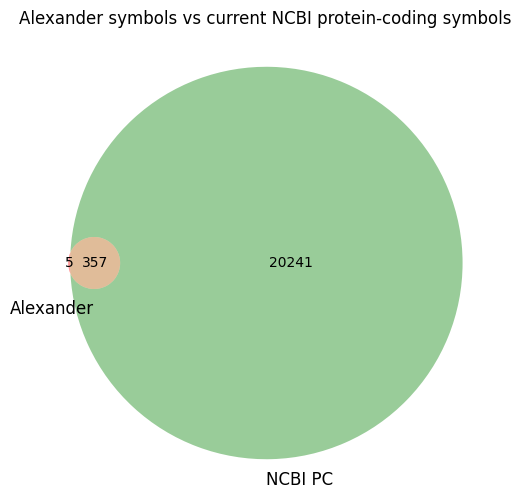

['H2BC20P', 'HSP90AA2P', 'POTEKP', 'SSX2; SSX2B', 'ST13P4']


In [6]:
fig, ax = plt.subplots(figsize=(6, 6))
venn2([alex_genes, pc_symbols], set_labels=("Alexander", "NCBI PC"), ax=ax)
ax.set_title("Alexander symbols vs current NCBI protein-coding symbols")
plt.show()
print(sorted(alex_genes - pc_symbols))

## Venn — Alexander vs DeepCover (raw)

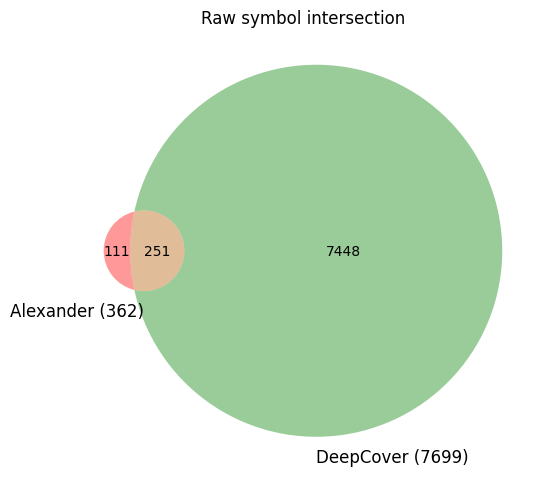

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
venn2([alex_genes, deepcover_bg], set_labels=(f"Alexander ({len(alex_genes)})", f"DeepCover ({len(deepcover_bg)})"), ax=ax)
ax.set_title("Raw symbol intersection")
plt.show()

## Venn — Alexander resolved to DeepCover's symbol

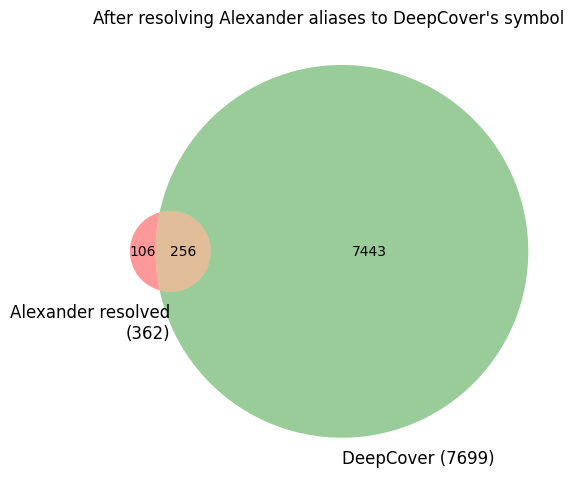

,alexander_input,deepcover_symbol,ncbi_gene_url
0,FERRY3,C12ORF4,https://www.ncbi.nlm.nih.gov/gene/57102
1,H1-6,HIST1H1T,https://www.ncbi.nlm.nih.gov/gene/3010
2,MACROH2A2,H2AFY2,https://www.ncbi.nlm.nih.gov/gene/55506
3,RIGI,DDX58,https://www.ncbi.nlm.nih.gov/gene/23586
4,STING1,TMEM173,https://www.ncbi.nlm.nih.gov/gene/340061


In [8]:
canonical_to_deepcover = {}
for g in deepcover_bg:
    if cur := ncbi_lookup(g):
        canonical_to_deepcover.setdefault(cur, g)

def alex_to_deepcover_symbol(g: str) -> str | None:
    G = g.upper()
    if G in deepcover_bg:
        return G
    return canonical_to_deepcover.get(ncbi_lookup(G))

# symbol -> NCBI gene_id for URL construction (covers all PC genes)
symbol_to_gene_id = dict(zip(ncbi_df["Symbol"].str.upper(), ncbi_df["GeneID"]))
def ncbi_url(symbol: str) -> str | None:
    canonical = ncbi_lookup(symbol) or symbol.upper()
    gid = symbol_to_gene_id.get(canonical)
    return f"https://www.ncbi.nlm.nih.gov/gene/{gid}" if gid else None

# Unresolved alex genes are kept under their original symbol so they appear in
# the alex-only region of the Venn (and not silently dropped).
alex_in_dc_namespace = {alex_to_deepcover_symbol(g) or g for g in alex_genes}

fig, ax = plt.subplots(figsize=(6, 6))
venn2([alex_in_dc_namespace, deepcover_bg],
      set_labels=(f"Alexander resolved\n({len(alex_in_dc_namespace)})", f"DeepCover ({len(deepcover_bg)})"), ax=ax)
ax.set_title("After resolving Alexander aliases to DeepCover's symbol")
plt.show()

recovered = sorted(g for g in alex_genes if g not in deepcover_bg and alex_to_deepcover_symbol(g))
pd.DataFrame([
    {
        "alexander_input": g,
        "deepcover_symbol": alex_to_deepcover_symbol(g),
        "ncbi_gene_url":    ncbi_url(g),
    }
    for g in recovered
])

## Per-mutation paired enrichment vs DeepCover MoA

In [9]:
DEEPCOVER = ["DeepCover MoA"]

results = {}
for m, (up, dn) in per_mut.items():
    df = ps.enrich_pair(
        up=sorted(up), down=sorted(dn),
        libraries=DEEPCOVER, top=20, sort_by="pvalue_reverse", pvalue_le=1.0,
    )
    results[m] = df
    print(f"{m}: up={len(up)}, down={len(dn)}, results={len(df)}")

R239H: up=61, down=123, results=0
R239C: up=34, down=67, results=0
R79C: up=63, down=70, results=0
R79H: up=57, down=75, results=0
R239G: up=54, down=90, results=0


### R239H

In [10]:
results["R239H"][["term", "nGeneIds", "adjPvalueMimic", "adjPvalueReverse", "mimickerOverlap", "reverserOverlap"]] if len(results["R239H"]) else "No enriched terms"

'No enriched terms'

### R239C

In [11]:
results["R239C"][["term", "nGeneIds", "adjPvalueMimic", "adjPvalueReverse", "mimickerOverlap", "reverserOverlap"]] if len(results["R239C"]) else "No enriched terms"

'No enriched terms'

### R79C

In [12]:
results["R79C"][["term", "nGeneIds", "adjPvalueMimic", "adjPvalueReverse", "mimickerOverlap", "reverserOverlap"]] if len(results["R79C"]) else "No enriched terms"

'No enriched terms'

### R79H

In [13]:
results["R79H"][["term", "nGeneIds", "adjPvalueMimic", "adjPvalueReverse", "mimickerOverlap", "reverserOverlap"]] if len(results["R79H"]) else "No enriched terms"

'No enriched terms'

### R239G

In [14]:
results["R239G"][["term", "nGeneIds", "adjPvalueMimic", "adjPvalueReverse", "mimickerOverlap", "reverserOverlap"]] if len(results["R239G"]) else "No enriched terms"

'No enriched terms'